# Машинное обучение, ФКН ВШЭ

## Практическое задание 4. Классификация

### Общая информация
Дата выдачи: 09.11.2023

Мягкий дедлайн: 22.11.2023

Жесткий дедлайн: 26.11.2023

### О задании

В этом задании вы:
- ознакомитесь с тем, что происходит "внутри" метода опорных векторов и логистической регрессии
- познакомитесь с калибровкой вероятности
- изучите методы трансформации переменных и методы отбора признаков
- попробуете оценить экономический эффект модели

----

#### Самостоятельная оценка результатов

Для удобства проверки, исходя из набора решенных задач, посчитайте свою максимальную оценку.

**Оценка**:

### Оценивание и штрафы

Каждая из задач имеет определенную «стоимость» (указана в скобках около задачи). Максимально допустимая оценка за работу — 10 баллов.

Сдавать задание после указанного жёсткого дедлайна нельзя. При выставлении неполного балла за задание в связи с наличием ошибок на усмотрение проверяющего предусмотрена возможность исправить работу на указанных в ответном письме условиях.

Задание выполняется самостоятельно. «Похожие» решения считаются плагиатом и все задействованные студенты (в том числе те, у кого списали) не могут получить за него больше 0 баллов (подробнее о плагиате см. на странице курса). Если вы нашли решение какого-то из заданий (или его часть) в открытом источнике, необходимо указать ссылку на этот источник в отдельном блоке в конце вашей работы (скорее всего вы будете не единственным, кто это нашел, поэтому чтобы исключить подозрение в плагиате, необходима ссылка на источник).

Неэффективная реализация кода может негативно отразиться на оценке.

### Формат сдачи

Для сдачи задания переименуйте получившийся файл *.ipynb в соответствии со следующим форматом: homework-practice-04-linclass-__Username__.ipynb, где Username — ваша фамилия и имя на латинице именно в таком порядке (например, homework-practice-04-linclass-__IvanovIvan__.ipynb).

# Часть 1. SVM, LR и калибровка вероятностей (2 балла + 0.5 бонус)

In [217]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

pd.set_option('display.max_rows', 100)
pd.set_option('display.max_columns', 100)

#### __Задание 1.1  Сравнение методов__ (0.5 балла)



Сгенерируем синтетические данные.

In [218]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split

# фиксируем random_state для воспроизводимости результатов
X, y = make_classification(
    n_samples=10000, n_features=10, n_informative=5, n_redundant=5, random_state=42)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

__Случайный классификатор__

Для начала зададим самую простую модель, которая на каждом объекте выдаёт случайный ответ. По тестовой выборке вычислим AUC-ROC, AUC-PR.

In [219]:
from sklearn.dummy import DummyClassifier
random_classifier = DummyClassifier(strategy='uniform', random_state=42).fit(X_train, y_train)
y_random = random_classifier.predict_proba(X_test)[:,1]
y_random

array([0.5, 0.5, 0.5, ..., 0.5, 0.5, 0.5])

In [220]:
from sklearn.metrics import (roc_curve, roc_auc_score, precision_recall_curve, average_precision_score)

fpr, tpr, thresholds = roc_curve(y_test, y_random)
roc_auc = roc_auc_score(y_test, y_random)
print("ROC-AUC:", roc_auc)
precison, recall, thresholds = precision_recall_curve(y_test, y_random)
pr_auc = average_precision_score(y_test, y_random)
print("PR-AUC:", pr_auc)

ROC-AUC: 0.5
PR-AUC: 0.5056666666666667


**Вопрос:** решаем задачу бинарной классификации, но y\_random содержит какие-то дробные числа, а не 0/1. Почему?



**Ответ**: predict_proba возвращает вероятности, а не классы

*Ниже приведен **пример** работы* со встроенными функциями `sklearn` для отрисовки ROC и PR кривых, сохранения метрик. Пайплайн можно изменять как вам удобно.

In [221]:
from sklearn.metrics import auc
from sklearn.metrics import average_precision_score
from sklearn.metrics import precision_recall_curve
from sklearn.metrics import PrecisionRecallDisplay

from sklearn.metrics import roc_auc_score
from sklearn.metrics import RocCurveDisplay

Random Classifier metrics


AUC-PR: 0.75283
AUC-ROC: 0.50000


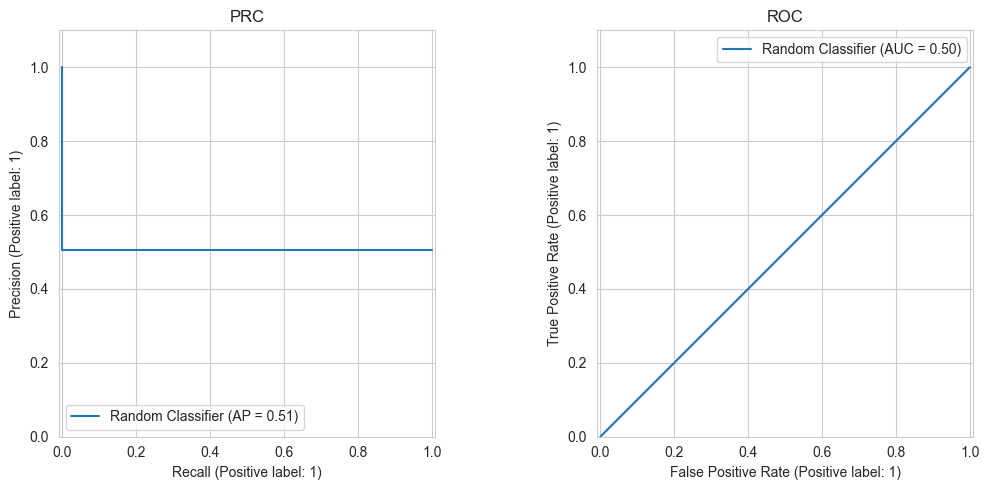

In [222]:
def depict_pr_roc(y_true, y_pred, classifier_name='Some Classifier', ax=None):
  if ax is None:
    fig, ax = plt.subplots(1, 2, figsize=(11, 5))

  print(classifier_name, 'metrics')
  PrecisionRecallDisplay.from_predictions(y_true, y_pred, ax=ax[0], name=classifier_name)
  precision, recall, _ = precision_recall_curve(y_true, y_pred)
  print('AUC-PR: %.5f' % auc(recall, precision))
  ax[0].set_title("PRC")
  ax[0].set_ylim(0, 1.1)

  RocCurveDisplay.from_predictions(y_true, y_pred, ax=ax[1], name=classifier_name)
  print('AUC-ROC: %.5f' % roc_auc_score(y_true, y_pred))
  ax[1].set_title("ROC")
  ax[1].set_ylim(0, 1.1)

  plt.tight_layout()
  plt.legend()


depict_pr_roc(y_test, y_random, 'Random Classifier')

In [223]:
# dataframe для сравнения
# методов классификации по метрикам
df_metrics = pd.DataFrame(columns=['AUC_PR', 'AUC_ROC', 'reg_const'])
precision, recall, _ = precision_recall_curve(y_test, y_random)
  # добавление очередной строки с характеристиками метода
df_metrics.loc['Random Classifier'] = [
      auc(recall, precision),
      roc_auc_score(y_test, y_random),
      0
]

  # по аналогии результаты следующих экспериментов можно будет собрать в табличку
df_metrics

,AUC_PR,AUC_ROC,reg_const
Random Classifier,0.752833,0.5,0.0


__Support Vector Machine (Linear Kernel)__

Обучите метод опорных векторов.

На занятиях мы проходили линейный вариант без ядрового перехода, что соответствует линейному ядру (`LinearSVC` или же `SVC(kernel='linear')` в `sklearn.svm`).

Подберите параметр регуляризации `C` с точки зрения AUC-PR (можете воспользоваться кросс-валидацией или отделить валидационную выборку от обучающей).


In [224]:
#your code here
from sklearn.svm import SVC
from sklearn.model_selection import KFold

C = np.logspace(-3, 0, 10)
means = []

for reg_const in C:
    X = X_train
    y = y_train
    kf = KFold(n_splits=4, shuffle=False)
    #kf.get_n_splits()

    auc_sum = 0
    for i, (train_index, test_index) in enumerate(kf.split(X)):
        model = SVC(kernel='linear', C=reg_const)
        model.fit(X_train[train_index], y_train[train_index])
        y_pred = model.predict(X_train[test_index])
        y_true = y_train[test_index]

        pr_auc = average_precision_score(y_true, y_pred)
        auc_sum += pr_auc
        #print(f"Fold {i}:")
        #print(f"  Train: index={train_index}")
        #print(f"  Test:  index={test_index}")
    means.append(auc_sum / 4)

means = np.array(means)
best_c = C[means.argmax()]

In [225]:
print(best_c)

0.004641588833612777


  На тестовой части:
  - постройте ROC и PR кривые,
  - посчитайте AUC-ROC, AUC-PR с точностью до 5 знаков

SVC(linear) metrics
AUC-PR: 0.83274
AUC-ROC: 0.77382


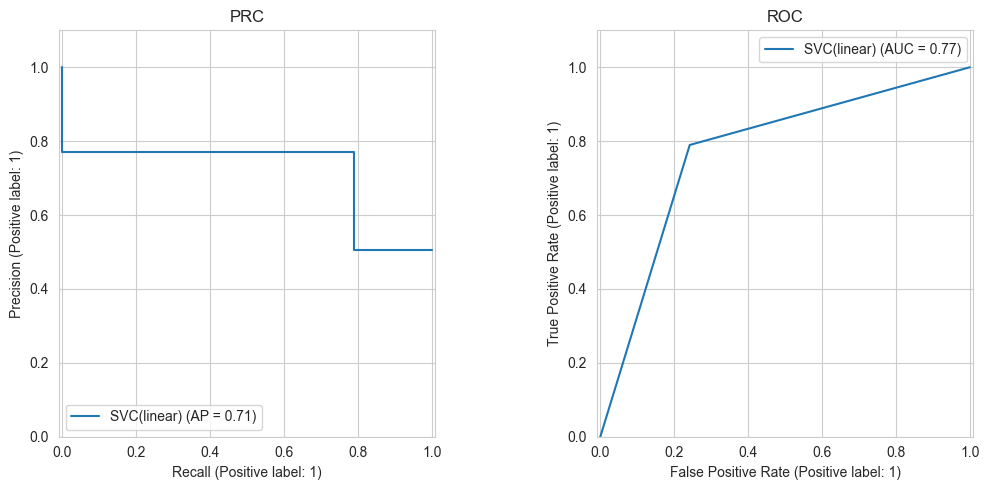

In [226]:
#your code here
model = SVC(kernel='linear', C=best_c)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

depict_pr_roc(y_test, y_pred, 'SVC(linear)')

Сравните AUC-ROC и AUC-PR для вашей модели с этими же метриками для случайного классификатора.

SVC(linear) metrics
AUC-PR: 0.75283
AUC-ROC: 0.50000


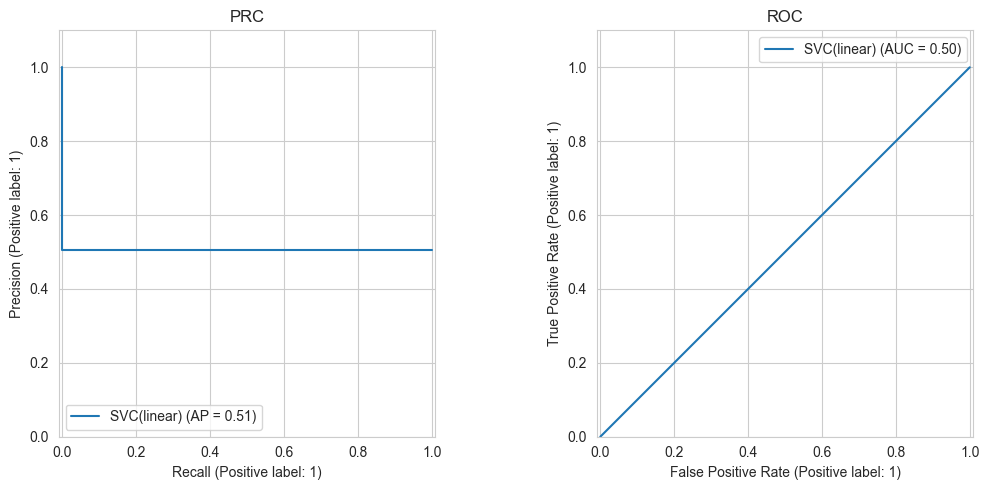

In [227]:
#your code here
depict_pr_roc(y_test, y_random, 'SVC(linear)')
model_svc = SVC(kernel='linear', C=best_c)

__Logistic Regression__


Аналогичное задание для логистической регрессии с L2 регуляризатором:


*   подберите гиперпараметр C, используя метрику AUC-PR
*   нарисуйте ROC, PR кривые для тестовой части
*   выведите метрики для тестовых данных и сравните их с результатами случайного классификатора



In [228]:
#your code here
#your code here
from sklearn.linear_model import LogisticRegression

C = np.logspace(-3, 0, 10)
means = []

for reg_const in C:
    X = X_train
    y = y_train
    kf = KFold(n_splits=4, shuffle=False)
    #kf.get_n_splits()

    auc_sum = 0
    for i, (train_index, test_index) in enumerate(kf.split(X)):
        model = LogisticRegression(C=reg_const)
        model.fit(X_train[train_index], y_train[train_index])
        y_pred = model.predict(X_train[test_index])
        y_true = y_train[test_index]

        pr_auc = average_precision_score(y_true, y_pred)
        auc_sum += pr_auc
        #print(f"Fold {i}:")
        #print(f"  Train: index={train_index}")
        #print(f"  Test:  index={test_index}")
    means.append(auc_sum / 4)

means = np.array(means)
best_c = C[means.argmax()]

In [229]:
model_LR = LogisticRegression(C=best_c)
print(best_c)

0.046415888336127774


Нарисуйте ROC, PR кривые для тестовой части для всех 3 классификаторов на одном графике

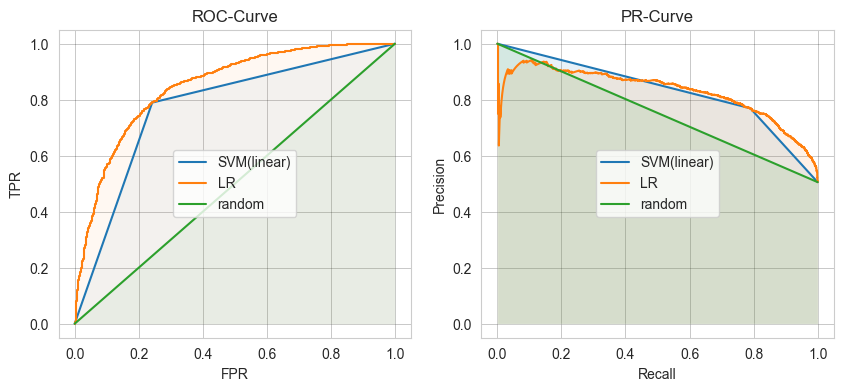

In [230]:
#your code here
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.base import BaseEstimator, TransformerMixin

fig, ax = plt.subplots(1, 2, figsize=(10, 4))

def plot_ROC(y_pred, y_true, axis, label=''):
    fpr, tpr, _ = roc_curve(y_true, y_pred)
    axis.plot(fpr, tpr, label = label)
    axis.fill_between(fpr, tpr, alpha=0.05)

def plot_PR(y_pred, y_true, axis, label=''):
    precision, recall, _ = precision_recall_curve(y_true, y_pred)
    axis.plot(recall, precision, label = label)
    axis.fill_between(recall, precision, alpha=0.1)

model_svc.fit(X_train, y_train)
model_LR.fit(X_train, y_train)
y_pred_svc = model_svc.predict(X_test)
y_pred_LR = model_LR.predict_proba(X_test)[:, 1]

preds = {
    'SVM(linear)' : y_pred_svc,
    'LR' : y_pred_LR,
    'random' : y_random
}
for key, val in preds.items():
    plot_ROC(val, y_test, axis=ax[0], label=key)
    plot_PR(val, y_test, axis=ax[1], label=key)

ax[0].grid(color='black', linestyle='-', linewidth=0.5, alpha=0.3)
ax[1].grid(color='black', linestyle='-', linewidth=0.5, alpha=0.3)

ax[0].set_title("ROC-Curve")
ax[0].set_xlabel("FPR")
ax[0].set_ylabel("TPR")
ax[1].set_title("PR-Curve")
ax[1].set_xlabel("Recall")
ax[1].set_ylabel("Precision")
ax[0].legend()
ax[1].legend()
plt.show()

**Вопрос:** Сравните результаты LR и SVM с точки зрения всех вычисленных критериев качества, объясните различия (если они есть).



**Ответ:** # your answer here

#### __Задание 1.2. Визуализация в подходах SVM, LR__ (0.5 балла)



В названии метода опорных векторов присутствуют некоторые "опорные векторы". По сути, это объекты из обучающей выборки, которые задали положение разделяющей гиперплоскости.

* Сгенерируйте синтетические данные с помощью `make_classification` __с 2 признаками__, обучите на нём метод опорных векторов. В этот раз воспользуйтесь `SVC(kernel='linear')`, так как только в нём есть информация об опорных векторах, а в `LinearSVC` нет. Не забудьте зафиксировать seed для воспроизводимости

* Визуализируйте разделяющую прямую, все объекты и выделите опорные векторы (атрибут `support_vectors_`).

[[1.82181136 0.16333141]] [0.32533161]


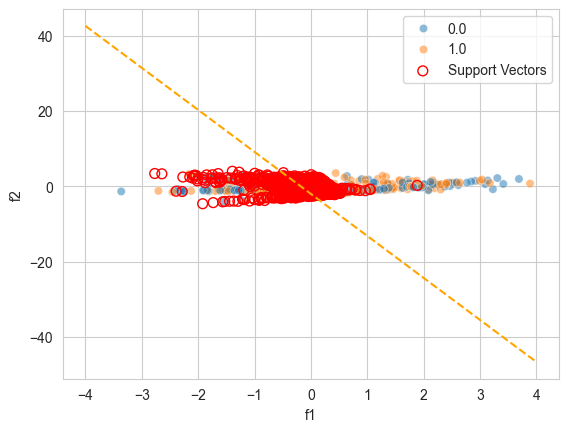

In [231]:
#your code here
import seaborn as sns
X, y = make_classification(n_samples=5000, n_features=2, n_classes=2, n_redundant=0, n_informative=2, random_state=55)
model_sv = SVC(kernel='linear')
X = pd.DataFrame(X, columns=['f1', 'f2'])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
model_sv.fit(X_train, y_train)

df_y_test = pd.DataFrame(y_test, columns=['y'])
df_test = pd.concat([X_test, df_y_test])
sns.scatterplot(data=df_test, x="f1", y="f2", hue="y", alpha=0.5)

plt.scatter(model_sv.support_vectors_[:, 0], model_sv.support_vectors_[:, 1],
            s=50, facecolors='none', edgecolors='r', label='Support Vectors')
x_points = np.linspace(-4, 4, 500)
coef = model_sv.coef_[0]
y_points = (-coef[0] * x_points - model_sv.intercept_) / coef[1] 
plt.plot(x_points, y_points, linestyle='--', color='orange')
plt.legend()
print(model_sv.coef_, model_sv.intercept_)

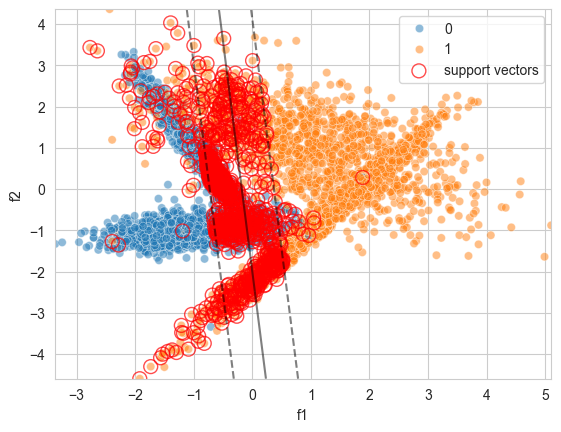

In [232]:
import warnings
warnings.filterwarnings('ignore')

def plot_svm_2D(X, y, model,  plot_support=True):

    X = np.array(X)
    #создали сетку
    xx = np.linspace(X[:,0].min(), X[:,0].max(), 30)
    yy = np.linspace(X[:,1].min(), X[:,1].max(), 30)
    YY, XX = np.meshgrid(yy, xx)
    xy = np.vstack([XX.ravel(), YY.ravel()]).T

    Z = model.decision_function(xy)
    Z = np.array(Z)
    Z = Z.reshape(30, 30)

    plt.contour(XX, YY, Z, levels=[-1, 0, 1], alpha=0.5, linestyles=['--', '-', '--'], colors='k')

    draw_df = pd.DataFrame(X, columns=['f1', 'f2'])
    draw_df = pd.concat([draw_df, 
                         pd.DataFrame(y, columns=['y'])], axis=1)
    sns.scatterplot(data=draw_df, x="f1", y="f2", hue="y", alpha=0.5)

    #Отрисовали опорные векторы
    if plot_support:
        plt.scatter(model_sv.support_vectors_[:, 0],
                model_sv.support_vectors_[:, 1],
                   label='support vectors',
                   s=100,
                   linewidth=1,
                   edgecolor="red",
                   facecolors='none',
                   alpha=0.7)

    plt.legend()

plot_svm_2D(X, y, model_sv)

**Вопрос:** какие объекты выделяются как "опорные"?


**Ответ:** 
Точки по которым строится разделительная прямая/плоскость

В отличие от метода опорных векторов, логистическая регрессия не пытается построить разделяющую гиперплоскость с максимальным отступом, а приближает в каждой точке пространства объектов вероятность положительных ответов $p(y=+1|x)$. Попробуйте нарисовать это распределение на плоскости, не забудьте отметить на ней все объекты.

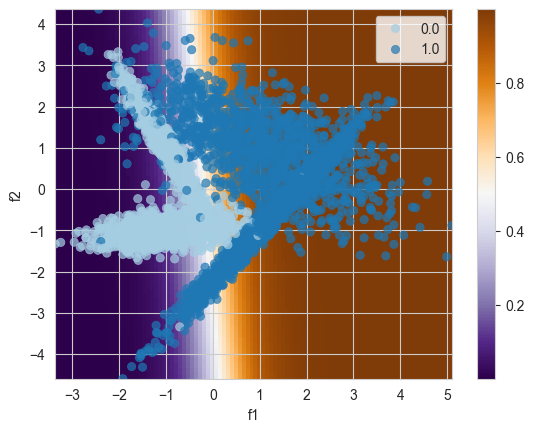

In [233]:
model_lr = LogisticRegression(C=best_c)
model_lr.fit(X_train, y_train)

def plot_logreg_2D(X, y, model):

    X = np.array(X)
    #создали сетку
    xx = np.linspace(X[:,0].min(), X[:,0].max(), 100)
    yy = np.linspace(X[:,1].min(), X[:,1].max(), 100)
    YY, XX = np.meshgrid(yy, xx)
    xy = np.vstack([XX.ravel(), YY.ravel()]).T

    #Ответы модели для сетки для отрисовки распределения
    Z = model.predict_proba(xy)[:, 1]
    Z = Z.reshape((xx.shape[0], -1)).T

    image = plt.imshow(Z, interpolation='nearest',
                       extent=(xx.min(), xx.max(), yy.min(), yy.max()),
                       aspect='auto', origin='lower', cmap=plt.cm.PuOr_r)

    #Отрисовали выборку
    data_df = pd.DataFrame(X, columns=["f1", "f2"])
    data_df = pd.concat([data_df, pd.DataFrame(y, columns=['y'])])

    sns.scatterplot(data=data_df, x="f1", y="f2", hue='y', palette='Paired', alpha=0.7, edgecolor=None)
                #cmap=plt.cm.Paired)
    plt.legend()

    plt.colorbar(image)


plot_logreg_2D(X, y, model_lr)

**Вопрос:** Как на картинке визуализирована область, где модель не уверена ($p(y=+1|x) = 0.5$)? Как это обосновать теоритечески?



**Ответ:** Как разделительная линия. Модель использует сигмоидную функцию для классификации, если p=0.5 то $-y_i \cdot W^{T}X = 0$

#### __Задание 2. Калибровка вероятностей__ (1 балл)



Перейдём к оценке качества выдаваемых алгоритмами вероятностей. Начнём с калибровочных кривых.

Допустим, алгоритм возвращает некоторые числа от нуля до единицы. Хорошо ли они оценивают вероятность?

Хорошо откалиброванный  классификатор должен выдавать значения так, чтобы среди образцов, для которых он дал значение, близкое к $\alpha$, примерно $\alpha * 100 \%$ фактически принадлежали к положительному классу. (Например, если классификатор выдает 0.3 для некоторых, то 30% из них должны принадлежать классу 1)

Для построения калибровочной криовой используем следующий алгоритм:

Разобьем отрезок $[0, 1]$ на несколько маленьких отрезков одинаковой длины.

Рассмотрим $i$-й отрезок с границами $[a_i, b_i]$ и предсказания $p_1, p_2, \dots, p_k$, которые попали в него. Пусть им соответствуют истинные ответы $y_1, y_2, \dots, y_k$. Если алгоритм выдает корректные вероятности, то среди этих истинных ответов должно быть примерно $(a_i + b_i) / 2$ единиц. Иными словами, если нарисовать кривую, у которой по оси X отложены центры отрезков, а по оси Y — доли единичных ответов этих в отрезках, то она должна оказаться диагональной.

Ниже приведена функция, которая должна рисовать такие кривые. В ней допущено две ошибки — найдите и исправьте их.

In [234]:
def plot_calibration_curve(y_test, preds, axis):
    bin_middle_points = []
    bin_real_ratios = []
    n_bins = 10

    for i in range(n_bins):
        l = 1.0 / n_bins * i
        r = 1.0 / n_bins * (i + 1)
        bin_middle_points.append((l + r) / 2)
        mask = (preds > l) & (preds <= r)
        bin_real_ratios.append(
            np.sum(y_test[mask]) / np.sum(mask)
        )

    plt.plot(bin_middle_points, bin_middle_points, linestyle='--')
    plt.plot(bin_middle_points, bin_real_ratios)

Сгенерируйте синтетические данные аналогично использованным в самом первом задании. Постройте калибровочные кривые на тестовой части для логистической регрессии и метода опорных векторов (не забудьте перевести его предсказания в $[0;1]$).

Отрисуйте калибровочную кривую идеально откалиброванной модели (диагональ)

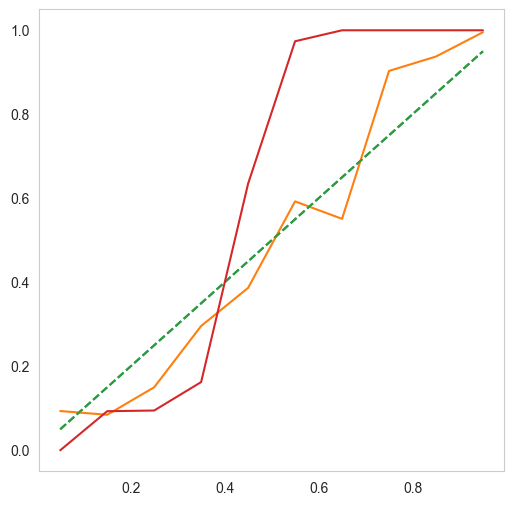

In [235]:
from sklearn.preprocessing import MinMaxScaler

pred_dec = model_sv.decision_function(X_test)

fig, ax = plt.subplots(figsize=(6, 6))

min_max = MinMaxScaler()
pred_dec = min_max.fit_transform(pred_dec.reshape(-1 ,1))

y_cal_proba = model_lr.predict_proba(X_test)[:, 1]
pred_dec = pred_dec[:, 0]

plot_calibration_curve(y_test, y_cal_proba, axis=ax)
plot_calibration_curve(y_test, pred_dec, axis=ax)
plt.ylim([-0.05, 1.05])
plt.grid()

**Вопрос**: хорошо ли откалиброваны кривые для SVM, логистической регрессии?

**Ответ:** logreg предсказывает вероятность, а svm метки. Отсюда видно что logreg откалиброван лучше

Изучите распределение ответов классификаторов (постройте гистограммы с помощью `plt.hist`).

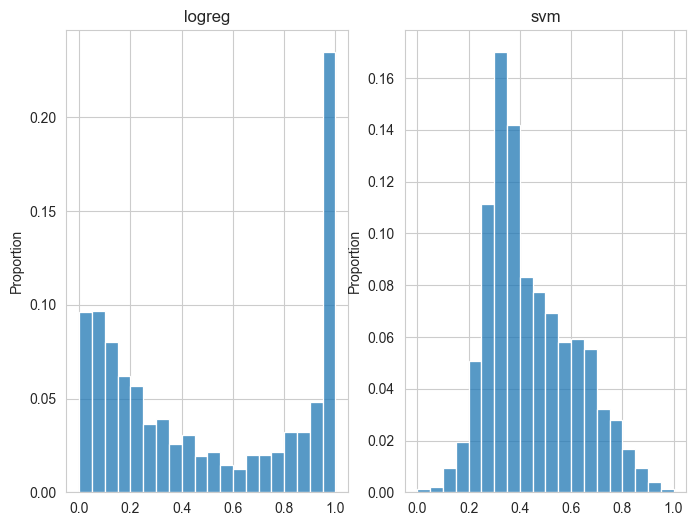

In [236]:
#your code here
sns.set_style("whitegrid")
fig, ax = plt.subplots(1, 2, figsize=(8, 6))
sns.histplot(y_cal_proba, ax=ax[0], stat='proportion', bins=20)
ax[0].set_title("logreg")
sns.histplot(pred_dec, ax=ax[1], stat='proportion', bins=20)
ax[1].set_title("svm")
plt.show()

**Вопрос:** Чем они различаются? Чем вы можете объяснить это?

**Ответ:** у logreg более тяжёлые хвосты. Minmax нормализует функцию через минимальное и максимальное значение, которое очень чувствительно к выбросам. Из-за этого большинство наблюдений остаётся где-то в середине. Также logloss сильно штрафует модель за веса не близкие к 0 или 1

Воспользуйтесь `CalibratedClassifierCV` из `sklearn` для калибровки вероятностей метода опорных векторов на обучении и постройте с его помощью  предсказания для тестовой выборки.

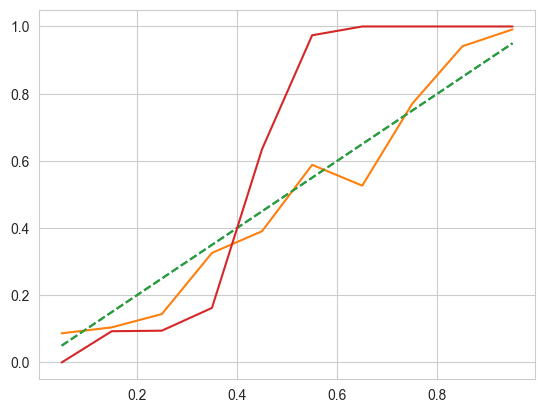

In [237]:
#your code here
from sklearn.calibration import CalibratedClassifierCV

calibrated_clf = CalibratedClassifierCV(model_sv)
calibrated_clf.fit(X_train, y_train)
y_dec_cal = calibrated_clf.predict_proba(X_test)[:, 1]

plot_calibration_curve(y_test, y_dec_cal, axis=ax)
plot_calibration_curve(y_test, pred_dec, axis=ax)
plt.ylim([-0.05, 1.05])
plt.grid(True)

**Вопрос:** Улучшилась ли калибровочная кривая?

**Ответ:** Значительно улучшилась

##### __Бонус: Авторское решение__ (0.5 балла)

Реализуйте свою функцию для калибровки вероятностей, используя любой из известных подходов. Кратко опишите ваш подход и продемонстрируйте результаты. Ключевые слова для вдохновения: `Platt`, `Isotonic`.

In [238]:
#your code here

# Часть 2. Обработка категориальных переменных (4 балла + 1.5 бонус)

Как мы знаем, перекодировать категориальную переменную в список чисел (к примеру 1, 2, 3, ..., n) плохо, поскольку это бы задало на множестве ее значений некоторый порядок, не имеющий смысла.

В этой части мы рассмотрим два основных способа обработки категориальных значений:
- One-hot-кодирование
- Счётчики (CTR, mean-target кодирование, ...) — каждый категориальный признак заменяется на среднее значение целевой переменной по всем объектам, имеющим одинаковое значение в этом признаке.

Начнём с one-hot-кодирования. Допустим наш категориальный признак $f_j(x)$ принимает значения из множества $C=\{c_1, \dots, c_m\}$. Заменим его на $m$ бинарных признаков $b_1(x), \dots, b_m(x)$, каждый из которых является индикатором одного из возможных категориальных значений:
$$
b_i(x) = [f_j(x) = c_i]
$$

#### __Подготовка данных__

(бесценный шаг)

Разберем датасет [покупок велосипедов](https://www.kaggle.com/datasets/heeraldedhia/bike-buyers/): даны признаки покупателя, требуется предсказать, купит ли он/она велосипед



Замените пропуски в категориальных переменных на новую категорию (`'undefined'`)

Разделите признаки на 2 таблицы: категориальные и числовые признаки

In [239]:
import kaggle
kaggle.api.authenticate()
kaggle.api.dataset_download_files('heeraldedhia/bike-buyers/', path='./data', unzip=True)

Dataset URL: https://www.kaggle.com/datasets/heeraldedhia/bike-buyers/versions/


In [240]:
df = pd.read_csv('./data/bike_buyers.csv')
#Заменим пропуски категориальных переменных
#your code here

X = df.drop(columns=['Purchased Bike'])
y = (df['Purchased Bike'] == 'Yes').astype('int64')

#Разделим на категориальные признаки и числовые
X_numerical = ["Income", "Children", "Cars", "Age"]
X_categorical = list( set(X.columns) - set(X_numerical + ["ID"]) )

X[X_categorical] = X[X_categorical].fillna('undefined')


В начале поработаем только с категориальными признаками

In [241]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X[X_categorical], y, test_size=0.25, random_state=777, stratify=y)

#### __Задание 3. OrdinalEncoder__  (0.5 балла)

Закодируйте категориальные признаки с помощью `OrdinalEncoder`. Посчитайте качество (в этом задании будем работать c __`AUC-PR`__) при применении логистической регрессии. Замерьте время, потребовавшееся на обучение модели, с учетом кодирования признаков.

Time (sec): 0.0233
Area (PR-AUC): 0.6013263628653809


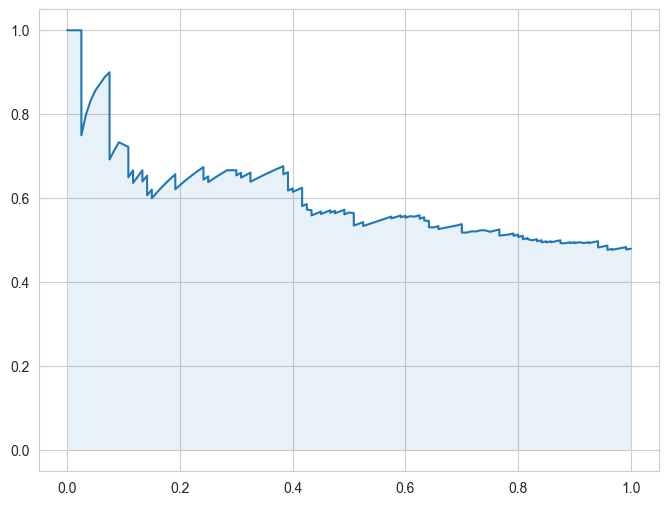

In [242]:
#your code here
from sklearn.preprocessing import OrdinalEncoder
from sklearn.compose import ColumnTransformer
import time

start_time = time.time_ns()

ct = ColumnTransformer([('ord', OrdinalEncoder(), X_categorical)])
X_train_enc = ct.fit_transform(X_train, y_train)
model_ord = LogisticRegression(C=best_c)
model_ord.fit(X_train_enc, y_train)

end_time = time.time_ns()
preds = model_ord.predict_proba(ct.transform(X_test))[:, 1]

fig, ax = plt.subplots(figsize=(8, 6))
plot_PR(preds, y_test, axis=ax)
print("Time (sec):", round((end_time - start_time) / 1e9, 4) )
print("Area (PR-AUC):", average_precision_score(y_test, preds))

#### __Задание 4. One-Hot Encoding__ (0.5 балла)



Закодируйте все категориальные признаки с помощью one-hot-кодирования. Обучите логистическую регрессию и посмотрите, как изменилось качество модели (в сравнении с тем, что было до кодирования). Измерьте время, потребовавшееся на кодирование категориальных признаков и обучение модели.

Time (sec): 0.0253
Area (PR-AUC): 0.6592123295558221


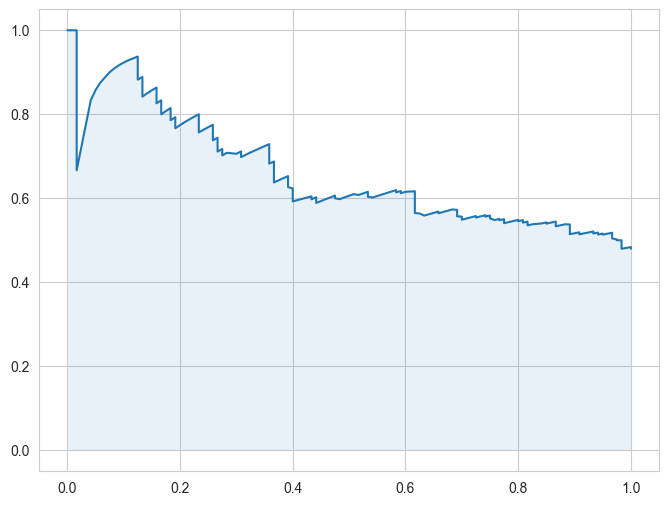

In [243]:
#your code here
from sklearn.preprocessing import OneHotEncoder
start_time = time.time_ns()

ct = ColumnTransformer([('ord', OneHotEncoder(sparse_output=False), X_categorical)])
X_train_enc = ct.fit_transform(X_train, y_train)
model_ord = LogisticRegression(C=best_c)
model_ord.fit(X_train_enc, y_train)

end_time = time.time_ns()
preds = model_ord.predict_proba(ct.transform(X_test))[:, 1]

fig, ax = plt.subplots(figsize=(8, 6))
plot_PR(preds, y_test, axis=ax)
print("Time (sec):", round((end_time - start_time) / 1e9, 4) )
print("Area (PR-AUC):", average_precision_score(y_test, preds))

Как можно заметить, one-hot-кодирование может сильно увеличивать количество признаков. Это сказывается на объеме необходимой памяти, особенно, если некоторый признак имеет большое количество значений.


#### __Задание 5. Mean-target Encoding__ (1 балл)

> Проблемы разрастания числа признаков можно избежать в другом способе кодирования категориальных признаков — mean-target encoding (для простоты будем называть это __счётчиками__). Сравним эффективность методов в рамках нашей маркетинговой задачи.

> Основная идея в том, что важны не сами категории, а значения целевой переменной, которые имеют объекты этой категории. Каждый категориальный признак мы заменим средним значением целевой переменной по всем объектам этой же категории:

$$
g_j(x, X) = \frac{\sum_{i=1}^{\ell} [f_j(x) = f_j(x_i)][y_i = +1]}{\sum_{i=1}^{\ell} [f_j(x) = f_j(x_i)]}
$$

Закодируйте категориальные переменные с помощью счётчиков (ровно так, как описано выше, без каких-либо хитростей). Обучите логистическую регрессию и посмотрите на качество модели на тестовом множестве.

Сравните время обучения с предыдущими экспериментами (с учетом кодирования признаков).

Time (sec): 0.0284
Area (PR-AUC): 0.6486235706507548


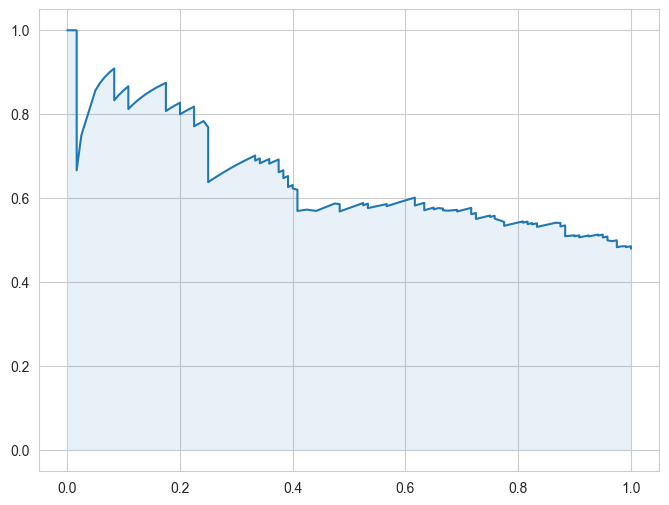

In [244]:
#your code here
#your code here
from sklearn.preprocessing import TargetEncoder
start_time = time.time_ns()

ct = ColumnTransformer([('ord', TargetEncoder(), X_categorical)])
X_train_enc = ct.fit_transform(X_train, y_train)
model_ord = LogisticRegression(C=best_c)
model_ord.fit(X_train_enc, y_train)

end_time = time.time_ns()
preds = model_ord.predict_proba(ct.transform(X_test))[:, 1]

fig, ax = plt.subplots(figsize=(8, 6))
plot_PR(preds, y_test, axis=ax)
print("Time (sec):", round((end_time - start_time) / 1e9, 4) )
print("Area (PR-AUC):", average_precision_score(y_test, preds))

##### __Бонус: Эффективная реализация (1 балл)__

Здесь и далее реализуйте вычисление счетчиков с помощью трансформера (наследуйтесь от классов `BaseEstimator, TransformerMixin` из `sklearn.base`). Обратите внимание, что все вычисления должны быть векторизованными, трансформер не должен модифицировать передаваемую ему выборку inplace, а все необходимые статистики нужно считать только по обучающей выборке в методе `fit`. Ваш трансформер должен принимать при инициализации список из категориальных признаков и изменять только их.

In [245]:
#your code here

_______

__Методы борьбы с переобучением счетчиков__


Отметим, что mean-target encoding признаки сами по себе являются классификаторами и, обучаясь на них, мы допускаем "утечку" целевой переменной в признаки. Это ведёт к __переобучению__, поэтому считать такие признаки необходимо таким образом, чтобы при вычислении для конкретного объекта его __целевая метка не использовалась__.

Это можно делать следующими способами:
1. Вычислять значение счётчика по всем объектам расположенным выше в датасете (например, если у нас выборка отсортирована по времени).
2. Вычислять по фолдам, то есть делить выборку на некоторое количество частей и подсчитывать значение признаков по всем фолдам кроме текущего (как делается в кросс-валидации).
3. Внесение некоторого шума в посчитанные признаки.

#### __Задание 6. Пошумим__  (0.5 балла)

Реализуйте корректное вычисление счётчиков самым простым способом — добавление шума к значениям.  При этом постарайтесь найти баланс между борьбой с переобучением и сохранением полезности признаков. Снова обучите логистическую регрессию, оцените качество.

Time (sec): 0.0102
Area (PR-AUC): 0.6384819314546776


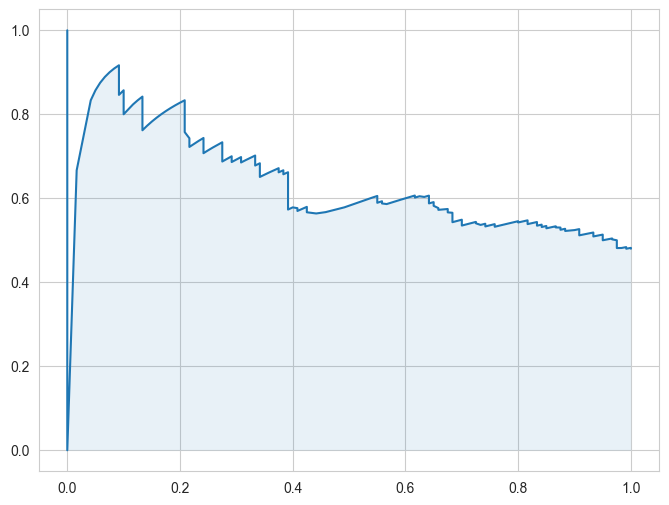

In [246]:
np.random.seed(42)
ct = ColumnTransformer([('ord', TargetEncoder(), X_categorical)])
ct.fit_transform(X_train, y_train)

X_train_trans = ct.transform(X_train)
df_train_enc = pd.DataFrame(X_train_trans, columns=X_categorical)

for i in X_categorical:
    vals = np.unique(df_train_enc[i]).astype(float)
    
    vals_new = vals + np.random.normal(loc=0, scale=0.02, size=len(vals))
    mapping = dict(zip(vals, vals_new))

    df_train_enc[i] = df_train_enc[i].map(mapping).astype(float)

start_time = time.time_ns()

model_ord.fit(df_train_enc, y_train)
preds = model_ord.predict_proba(ct.transform(X_test))[:, 1]

end_time = time.time_ns()

fig, ax = plt.subplots(figsize=(8, 6))
plot_PR(preds, y_test, axis=ax)

print("Time (sec):", round((end_time - start_time) / 1e9, 4))
print("Area (PR-AUC):", average_precision_score(y_test, preds))

**Вопрос:** Сделайте выводы. Помогло ли добавление шума? Почему?

**Ответ:** Добавление шума помогло уменьшить утечку данных что немного улучшило модель. Неправильно подобранный шум же наоборот может сломать разделение 

##### __Бонус: другой подход__ (0.5 балла)

Посчитайте корректные счётчики первым или вторым способов из описанных выше (не забудьте добавить и шум).




In [247]:
#your code here

#### __Задание 7. Сглаживание счетчиков__  (1 балл)

> Теперь ответим на следующий вопрос: что будет, если некоторая категория встречается в выборке всего несколько раз? По этой причине производится сглаживание счётчиков. Например, на практике хорошие результаты показывает использование сглаживания средним по всей выборке:
$$
g_j(x, X) = \frac{\sum_{i=1}^{\ell} [f_j(x) = f_j(x_i)][y_i = +1] + C \times global\_mean}{\sum_{i=1}^{\ell} [f_j(x) = f_j(x_i)] + C}
$$
где $global\_mean$ — доля объектов положительного класса в выборке, $C$ — параметр, определяющий степень сглаживания (можно использовать 10 или подобрать для каждого признака свой). Идея в том, что мы "разбавляем" среднее значение по категории глобальным средним значением. И тем меньше, чем большее количество объектов этой категории встречается в выборке.

> Вместо среднего значения целевой переменной для сглаживания можно использовать любое другое значение от 0 до 1 (этот параметр иногда называют $prior$). Можно сделать несколько признаков с разными значениями параметра. На практике в задачах бинарной классификации полезными бывают даже отрицательные значения!

Добавьте сглаживание, описанное выше и повторите эксперименты. Подберите $C$, чтобы качество было лучше, чем при использовании One-Hot-Encoding


Time (sec): 0.0133
Area (PR-AUC): 0.6704955134561275


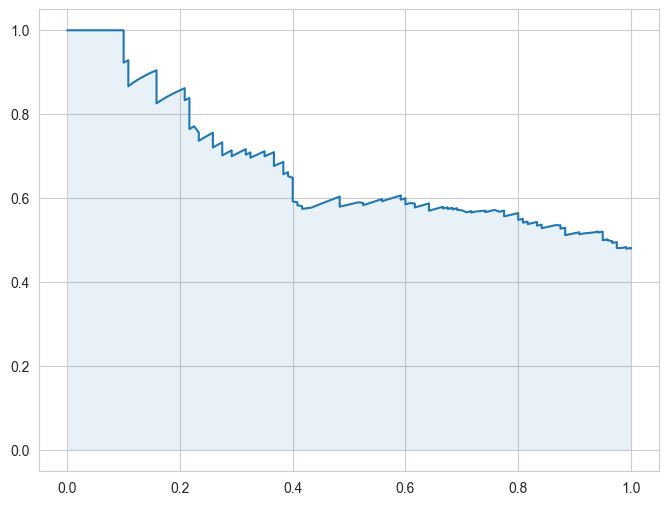

In [248]:
#your code here
np.random.seed(42)
global_mean = y_train.mean()
df_train = pd.concat([X_train, y_train], axis=1)
df_test = pd.DataFrame(X_test, columns=X_categorical)
C = 10

#Or use TargetEncoder(smooth=('auto'|float))
for i in X_categorical:
    temp = df_train.groupby(i)["Purchased Bike"].agg(["sum", "count"])
    temp['count'] += C
    temp['mean'] = (temp['sum'] + C * global_mean) / temp['count']
    temp = temp.reset_index()
    mapping = dict(zip(temp[i], temp["mean"]))
    df_train[i] = df_train[i].map(mapping).astype(float)
    df_test[i] = df_test[i].map(mapping).astype(float)

start_time = time.time_ns()

df_train = df_train.drop(columns=["Purchased Bike"])
model_ord.fit(df_train, y_train)

preds = model_ord.predict_proba(df_test)[:, 1]

end_time = time.time_ns()

fig, ax = plt.subplots(figsize=(8, 6))
plot_PR(preds, y_test, axis=ax)

print("Time (sec):", round((end_time - start_time) / 1e9, 4))
print("Area (PR-AUC):", average_precision_score(y_test, preds))


#### **Задание 8. Числовые или категориальные?**  (0.5 балла)

Теперь добавим числовые признаки к признакам-счетчикам.


В данных есть пропуски - замените их средним значением признака



In [249]:
#your code here
X[X_numerical] = X[X_numerical].fillna(X[X_numerical].mean())

 Сейчас для числовых признаков мы ищем линейную зависимость, что в общем случае  может быть неверной гипотезой. Тем не менее, у этих признаков есть довольно много уникальных значений (сколько?), поэтому применять к ним one-hot кодирование может оказаться излишним. Попробуйте закодировать эти признаки с помощью счетчиков (вместе и по отдельности). Стало ли лучше?

OHE: 80
Time (sec): 0.0133
Area (PR-AUC): 0.640401491253655


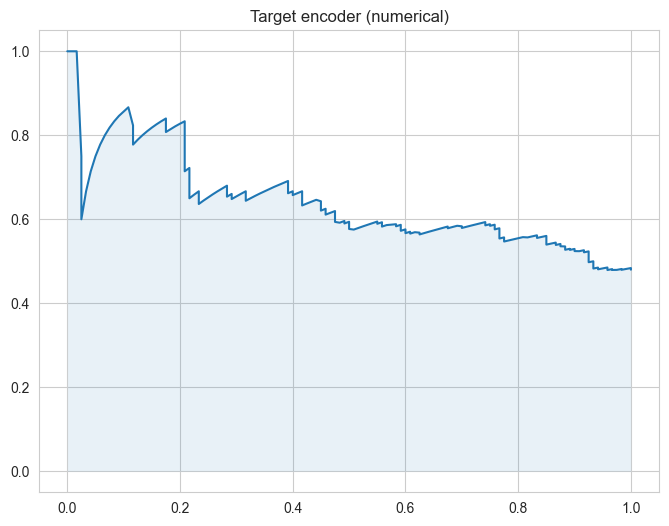

In [250]:
#your code here
ctohe = ColumnTransformer([
    ('ohe', OneHotEncoder(sparse_output=False, drop='first', handle_unknown='ignore'), X_numerical)
])

ohe_df = ctohe.fit_transform(X, y)
print("OHE:", ohe_df.shape[1] )

ctnum = ColumnTransformer([
    ('target', TargetEncoder(), X_numerical)
])

X_train, X_test, y_train, y_test = train_test_split(X[X_numerical], y, 
                                                    random_state=777, stratify=y)

start_time = time.time_ns()
df_num = ctnum.fit_transform(X_train, y_train)

model_ord.fit(df_num, y_train)

preds = model_ord.predict_proba(ctnum.transform(X_test))[:, 1]

end_time = time.time_ns()

fig, ax = plt.subplots(figsize=(8, 6))
ax.set_title("Target encoder (numerical)")
plot_PR(preds, y_test, axis=ax)

print("Time (sec):", round((end_time - start_time) / 1e9, 4))
print("Area (PR-AUC):", average_precision_score(y_test, preds))

Time (sec): 0.0534
Area (PR-AUC): 0.6291970573798684


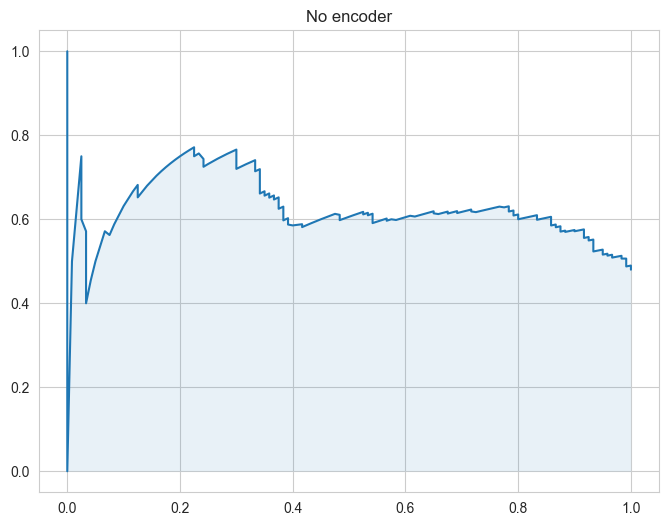

In [251]:
start_time = time.time_ns()

model_ord.fit(X_train, y_train)

preds = model_ord.predict_proba(X_test)[:, 1]

end_time = time.time_ns()

fig, ax = plt.subplots(figsize=(8, 6))

ax.set_title("No encoder")
plot_PR(preds, y_test, axis=ax)

print("Time (sec):", round((end_time - start_time) / 1e9, 4))
print("Area (PR-AUC):", average_precision_score(y_test, preds))

Time (sec): 0.0163
Area (PR-AUC): 0.6312959300665513


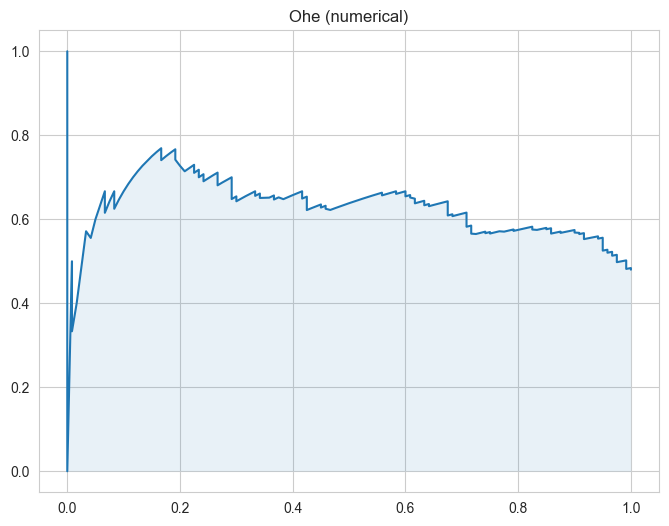

In [252]:
X_train_enc = ctohe.fit_transform(X_train)

start_time = time.time_ns()

model_ord.fit(X_train_enc, y_train)

preds = model_ord.predict_proba(ctohe.transform(X_test))[:, 1]

end_time = time.time_ns()

fig, ax = plt.subplots(figsize=(8, 6))

ax.set_title("Ohe (numerical)")
plot_PR(preds, y_test, axis=ax)

print("Time (sec):", round((end_time - start_time) / 1e9, 4))
print("Area (PR-AUC):", average_precision_score(y_test, preds))

> __Замечание.__ Усложнение методов вычисления счётчиков не делают результаты модели гарантированно лучше. Особенно с учётом того, что логистическая регрессия не такая сложная модель, чтобы переобучаться. Поэтому вы необязательно должны были получать на каждом шаге всё лучшие и лучшие результаты (но необходимые результаты у вас должны были получиться).



Как мы могли пронаблюдать, счётчики являются конкурентной альтернативой one-hot-кодированию. Опишите, какие плюсы и минусы использования счётчиков по сравнению с one-hot-кодированием вы заметили.

__Ответ:__ 

Плюсы: меньше столбцов(память + время), подходит для признаков с большим количеством разных значений

Минусы: страдают нелинейные зависимости(переводит все в непрерывуню шкалу), зависит от лейбла

# Часть 3. Отбор признаков (2 балла)

Загрузим данные [UCI Adult Dataset](https://archive.ics.uci.edu/ml/datasets/Adult). Этот набор данных содержит информацию о годовых доходах отдельных людей. В качестве признакового описания используется различная информация о человеке (образование, профессия, брачный статус и т.д.). Целевая переменная является бинарной: больше ли годовой доход 50K долларов или нет.

In [253]:
columns = ['age', 'workclass', 'fnlwgt', 'education',
           'education-num', 'marital-status', 'occupation',
           'relationship', 'race', 'sex', 'capital-gain',
           'capital-loss', 'hours-per-week', 'native-country',
           'income']
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"

df = pd.read_csv(url, header=None, names=columns)
df['income'] = (df['income'] != " <=50K").astype('int32')
df.sample()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
4667,17,Private,48610,11th,7,Never-married,Farming-fishing,Own-child,White,Male,0,0,45,United-States,0


Важной частью процесса построения модели является отбор признаков. На практике многие признаки оказывают малое влияние на модель (при этом их расчёт занимает время) или даже негативно сказываются на качестве модели. Попробуем несколько подходов отбора признаков, оценим, как они влияют на качество модели и сколько времени занимают.



Разделите выборку на обучающую и тестовую в соотношении 3:1. Зафиксируйте `random_state=777`, также используйте `stratify`.

In [254]:
#your code here
X = df.drop(columns=["income"])
y = df["income"]

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=777, test_size=0.25, stratify=y)

Давайте закодируем все категориальные признаки с помощью One-hot Encoding. Сколько новых признаков мы получим?

In [255]:
#your code here
X_categorical = ["workclass", "fnlwgt", "education", "marital-status", "occupation",	
                 "relationship", "race", "sex", "native-country"]

ctohe = ColumnTransformer([
    ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False, drop='first'), X_categorical)
])

start_time = time.time_ns()

X_train_enc = ctohe.fit_transform(X_train, y_train)

print( "#Features:", X_train_enc.shape[1] )

"""
Less columns for future tasks
"""
last = X_train_enc.shape[1]
X_train_enc = np.concatenate([X_train_enc[:, :200], X_train_enc[:, last-200:last]], axis=1)
print(X_train_enc.shape)

#Features: 17630
(24420, 400)


В качестве основной модели будем использовать логистическую регрессию, а целевой метрики — `AUC-PR`. Обучите модель и посчитайте качество на тестовой выборке. Давайте запомним полученное значение.

Time (sec): 8.0238
Area (PR-AUC): 0.6870459676618795


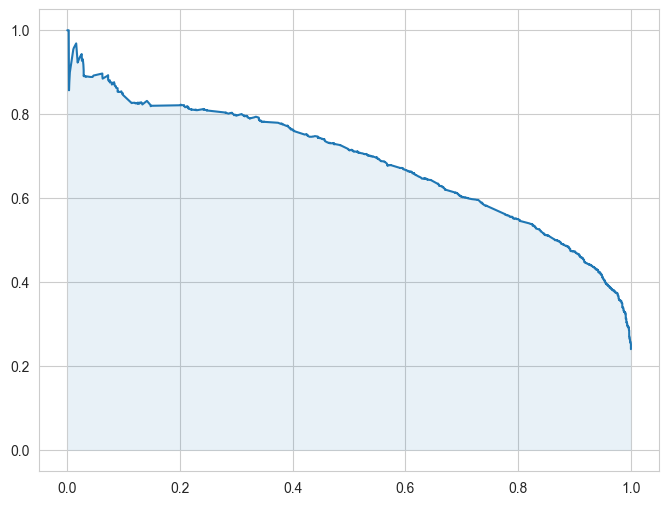

In [256]:
#your code here
model_ord.fit(X_train_enc, y_train)

"""
crutch
"""
buf_temp = ctohe.transform(X_test)
buf_temp = np.concatenate([buf_temp[:, :200], buf_temp[:, last-200:last]], axis=1)

preds = model_ord.predict_proba(buf_temp)[:, 1]

end_time = time.time_ns()

fig, ax = plt.subplots(figsize=(8, 6))

plot_PR(preds, y_test, axis=ax)

print("Time (sec):", round((end_time - start_time) / 1e9, 4))
print("Area (PR-AUC):", average_precision_score(y_test, preds))

#### __Задание 9. Встроенные методы (0.5 балла)__

Допустим, мы хотим оставить только 40 лучших признаков. Попробуем сделать это несколькими способами.

Начнём с отборам признаков с помощью линейной модели. Как известно, веса линейной модели означают вклад каждого признака в предсказание модели, а значит, модуль этого вклада можно интерпретировать как важность признаков. Такой метод отбора называются встроенным или embedded method, так как он заложен в особенности модели.

Оставьте 40 признаков с наибольшим модулем соответствующего параметра линейной модели. Обучите модели заново и оцените её качество. Замерьте скорость такого отбора признаков.



Time (sec): 0.9071
Area (PR-AUC): 0.2672296334279278


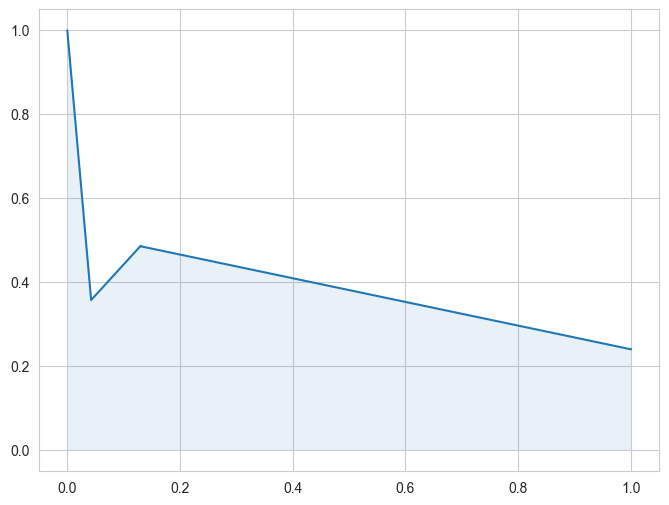

In [257]:
#your code here

coefs = list(enumerate(*model_ord.coef_))

coefs_sorted = sorted(coefs, key = lambda x : abs(x[1]), reverse=True)
best_40 = np.array(coefs_sorted[:40]).astype(int)[:, 0]

#print(coefs_sorted[:40])

start_time = time.time_ns()
model_ord.fit(X_train_enc[:, best_40], y_train)
preds = model_ord.predict_proba(ctohe.transform(X_test)[:, best_40])[:, 1]
#print(best_40)
end_time = time.time_ns()

fig, ax = plt.subplots(figsize=(8, 6))

plot_PR(preds, y_test, axis=ax)

print("Time (sec):", round((end_time - start_time) / 1e9, 4))
print("Area (PR-AUC):", average_precision_score(y_test, preds))


Изменилось ли качество? Как?

Модель стала гораздо эффективнее

Подумаем, что мы не учли. Мы действовали в предположении, что признаки вносят вклад равномерно, и не учитывали их масштаб. Если мы умножим один из признаков в 100 раз, то без учёта регуляризации его вес уменьшится в эти же 100 раз. А мы на основе этого отбираем признаки! Давайте сначала отмасштабируем признаки одним из способов, а только потом будем удалять признаки.

Кстати, в таком случае надо пересчитать качество на всех признаках (сделайте это ниже). Если вы сделали нормирование признаков в самом начале, то попробуйте отобрать признаки на неотмасштабированных данных.

Что получилось?

Результат не изменился. Возможно числовые признаки уже отмасштабированы или не вносят значительного вклада в результат

Time (sec): 1.0403
Area (PR-AUC): 0.678018023405843


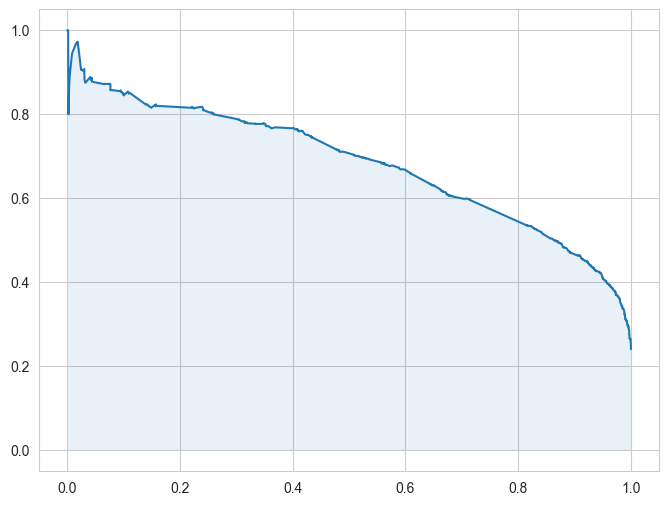

In [258]:
#your code here

#Scaling all features including OHE ones
minmaxct = ColumnTransformer([
    ('minmax', MinMaxScaler(), slice(0, X_train_enc.shape[1]))
])
X_train_scaled = minmaxct.fit_transform(X_train_enc)

start_time = time.time_ns()
model_ord.fit(X_train_scaled, y_train)

coefs = list(enumerate(*model_ord.coef_))
coefs_sorted = sorted(coefs, key = lambda x : abs(x[1]), reverse=True)
best_40 = np.array(coefs_sorted[:40]).astype(int)[:, 0]

model_ord.fit(X_train_enc[:, best_40], y_train)

res = ctohe.transform(X_test)
res = np.concatenate([res[:, :200], res[:, last-200:last]], axis=1)
res = minmaxct.transform(res)



preds = model_ord.predict_proba(res[:, best_40])[:, 1]

end_time = time.time_ns()

fig, ax = plt.subplots(figsize=(8, 6))

plot_PR(preds, y_test, axis=ax)

print("Time (sec):", round((end_time - start_time) / 1e9, 4))
print("Area (PR-AUC):", average_precision_score(y_test, preds))


Вопрос на засыпку: one-hot кодирование возвращает нам единичные признаки-индикаторы. Попробуйте также отскалировать их, как и обычные числовые, и снова выбрать 40 главных по вкладу признаков. Изменился ли их список? Изменится ли качество?

Нет, так как 0 или 1 останутся такими же 0 и 1

In [259]:
#your code here
"""
#your code here
#Scaling all features including OHE ones
minmaxct = ColumnTransformer([
    ('minmax', MinMaxScaler(), slice(0, X_train_enc.shape[1]))
])
X_train_scaled = minmaxct.fit_transform(X_train_enc)

start_time = time.time_ns()
model_ord.fit(X_train_scaled, y_train)

coefs = list(enumerate(*model_ord.coef_))
coefs_sorted = sorted(coefs, key = lambda x : abs(x[1]), reverse=True)
best_40 = np.array(coefs_sorted[:40]).astype(int)[:, 0]

model_ord.fit(X_train_enc[:, best_40], y_train)

res = ctohe.transform(X_test)
res = np.concatenate([res[:, :200], res[:, last-200:last]], axis=1)
res = minmaxct.transform(res)



preds = model_ord.predict_proba(res[:, best_40])[:, 1]

end_time = time.time_ns()

fig, ax = plt.subplots(figsize=(8, 6))

plot_PR(preds, y_test, axis=ax)

print("Time (sec):", round((end_time - start_time) / 1e9, 4))
print("Area (PR-AUC):", average_precision_score(y_test, preds))
"""

'\n#your code here\n#Scaling all features including OHE ones\nminmaxct = ColumnTransformer([\n    (\'minmax\', MinMaxScaler(), slice(0, X_train_enc.shape[1]))\n])\nX_train_scaled = minmaxct.fit_transform(X_train_enc)\n\nstart_time = time.time_ns()\nmodel_ord.fit(X_train_scaled, y_train)\n\ncoefs = list(enumerate(*model_ord.coef_))\ncoefs_sorted = sorted(coefs, key = lambda x : abs(x[1]), reverse=True)\nbest_40 = np.array(coefs_sorted[:40]).astype(int)[:, 0]\n\nmodel_ord.fit(X_train_enc[:, best_40], y_train)\n\nres = ctohe.transform(X_test)\nres = np.concatenate([res[:, :200], res[:, last-200:last]], axis=1)\nres = minmaxct.transform(res)\n\n\n\npreds = model_ord.predict_proba(res[:, best_40])[:, 1]\n\nend_time = time.time_ns()\n\nfig, ax = plt.subplots(figsize=(8, 6))\n\nplot_PR(preds, y_test, axis=ax)\n\nprint("Time (sec):", round((end_time - start_time) / 1e9, 4))\nprint("Area (PR-AUC):", average_precision_score(y_test, preds))\n'

#### __Задание 10. Методы фильтрации (0.5 балла)__


Давайте отбирать признаки умнее, а именно через подсчёт некоторой функции для каждого признака. На основании значений этой функции будем оставлять наиболее важные признаки. Методы этого семейства называют фильтрующими или  filter methods.

В качестве такой функции будем считать t-статистику:

$$t(j) = \frac{|\mu_+ - \mu_-|}{\sqrt{\frac{n_+ \sigma^2_+ + n_- \sigma^2_-}{n_+ + n_-}}},$$

где $\mu$, $\sigma$, $n$ соответственно среднее, стандартное отклонение и количество объектов каждого из классов.

Оставьте 40 признаков с наибольшим значением $t$, замерьте качество и скорость отбора признаков.



In [260]:
#your code here
t = []

for i in range(X_train_scaled.shape[1]):
    pos_mask = (y_train == 1)
    neg_mask = (y_train == 0)

    n_pos = pos_mask.sum()
    n_neg = neg_mask.sum()
    N = len(y_train)

    mu_p = X_train_scaled[:, i][pos_mask].sum() / n_pos
    mu_n = X_train_scaled[:, i][neg_mask].sum() / n_neg
    num = abs(mu_p - mu_n)

    denom = n_pos * X_train_scaled[:, i][pos_mask].var() + n_neg * X_train_scaled[:, i][neg_mask].var()
    denom = np.sqrt(denom / N)

    t.append(num / denom)

#print(t[:20])

Time (sec): 1.0403
Area (PR-AUC): 0.6824570639892384


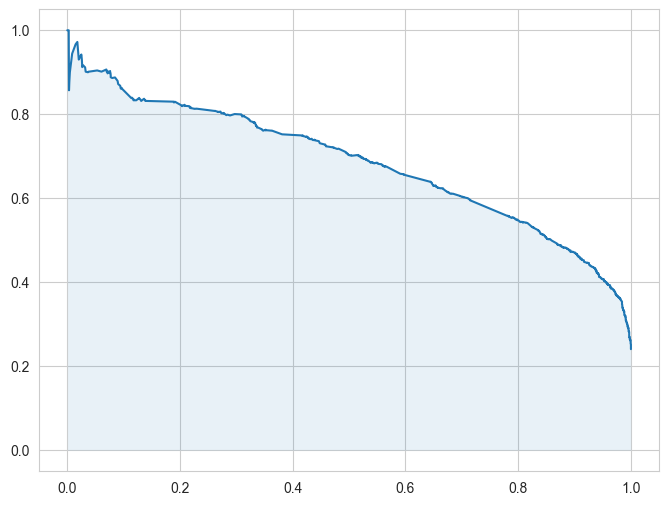

In [261]:
coefs = list(enumerate(t))
coefs_sorted = sorted(coefs, key = lambda x : abs(x[1]), reverse=True)
best_40 = np.array(coefs_sorted[:40]).astype(int)[:, 0]

#print(coefs_sorted[:40])

model_ord.fit(X_train_enc[:, best_40], y_train)

res = ctohe.transform(X_test)
res = np.concatenate([res[:, :200], res[:, last-200:last]], axis=1)
res = minmaxct.transform(res)

preds = model_ord.predict_proba(res[:, best_40])[:, 1]

fig, ax = plt.subplots(figsize=(8, 6))

plot_PR(preds, y_test, axis=ax)

print("Time (sec):", round((end_time - start_time) / 1e9, 4))
print("Area (PR-AUC):", average_precision_score(y_test, preds))

#### __Задание 11. Методы-обёртки__ (1 балл)

Третий из рассматриваемых нами методов работает следующим образом: мы исключаем по очереди один из признаков и смотрим, как это влияет на качество. Удаляем признаки таким жадным способом, пока не окажется выполненым некоторое условие (количество признаков или ухудшение качества). Более конкретно, на каждом шаге мы будем удалять такой признак $j$, что качество модели на множестве оставшихся признаков без $j$ максимально, то есть удалять мы будем наиболее бесполезный признак.

Заметим, что нельзя оценивать качество по тестовой выборке, иначе мы можем переобучиться, как, например, при настройке гиперпараметров. Разделите обучающую выборку на 2 части, на одной из них обучайте модель без одного из признаков,  на второй части оценивайте качество. Исходную тестовую выборку стоит использовать только для финальной оценки качества.

Снова оставьте только 40 признаков и оцените качество на тестовой выборке. Сколько времени занял такой отбор признаков?

In [262]:
#your code here
"""
features = np.arange(400)

while len(features) > 40:
    worst_f = 0
    worst_auc = 10

    for f in features:
        kf = KFold(n_splits=2)

        auc_mean = 0
        for train_index, test_index in kf.split(X_train_scaled):
            model_ord.fit(X_train_scaled[np.ix_(train_index, features)], 
                          y_train.iloc[train_index])
            preds = model_ord.predict_proba(X_train_scaled[test_index])[:, 1]
            auc_sum += average_precision_score(y_train.iloc[test_index], preds)
        auc_mean /= 2

        if auc_mean < worst_auc:
            worst_auc = auc_mean
            worst_f = f
    print("end")
    
    features.remove(worst_f) 
    break
"""

'\nfeatures = np.arange(400)\n\nwhile len(features) > 40:\n    worst_f = 0\n    worst_auc = 10\n\n    for f in features:\n        kf = KFold(n_splits=2)\n\n        auc_mean = 0\n        for train_index, test_index in kf.split(X_train_scaled):\n            model_ord.fit(X_train_scaled[np.ix_(train_index, features)], \n                          y_train.iloc[train_index])\n            preds = model_ord.predict_proba(X_train_scaled[test_index])[:, 1]\n            auc_sum += average_precision_score(y_train.iloc[test_index], preds)\n        auc_mean /= 2\n\n        if auc_mean < worst_auc:\n            worst_auc = auc_mean\n            worst_f = f\n    print("end")\n    \n    features.remove(worst_f) \n    break\n'

In [263]:
"""
from sklearn.feature_selection import SequentialFeatureSelector
kf = KFold(n_splits=2, shuffle=True, random_state=42)

sfs = SequentialFeatureSelector(
    estimator=model_ord,
    n_features_to_select=40,
    direction='forward',
    scoring='roc_auc',
    cv=kf,
    n_jobs=-1
)

sfs.fit(X_train_scaled, y_train)
selected_features = np.where(sfs.get_support())[0]
print("Отобранные признаки:", selected_features)
"""

'\nfrom sklearn.feature_selection import SequentialFeatureSelector\nkf = KFold(n_splits=2, shuffle=True, random_state=42)\n\nsfs = SequentialFeatureSelector(\n    estimator=model_ord,\n    n_features_to_select=40,\n    direction=\'forward\',\n    scoring=\'roc_auc\',\n    cv=kf,\n    n_jobs=-1\n)\n\nsfs.fit(X_train_scaled, y_train)\nselected_features = np.where(sfs.get_support())[0]\nprint("Отобранные признаки:", selected_features)\n'

Стоит отметить, что с помощью такого метода можно пойти и в обратную сторону. Попробуйте _добавлять_ по одному самому полезному признаку в выборку до тех пор, пока не наберется 40 штук. Найдется ли порог, при котором добавление следующих признаков будет только ухудшать качество модели?

In [264]:
#your code here

Слишком долго компилится, поэтому скипну :) (код рабочий)

Давайте подведём итоги по отбору признаков. Назовите преимущества и недостатки каждого из методов. Какой метод привёл к наилучшему качеству?

**Ответ:**

Коэффициент

Минусы: Ловит только линейные связи, чувствителен к масштабу

Плюсы: Быстро вычисляется

Т-статистика

Минусы: Игнорирует комбинации

Плюсы: Статистическая интерпретация, самое быстрое вычисление, ловит не только линейные вещи, не чувствительна к масштабу

Жадник

Минусы: Очень долго работает

Плюсы: Ловит синергии, риск переобучения

# Часть 4. Оценка экономического эффекта модели (2 балла)



В данной части мы займемся тем, что от вас скорее всего потребуется на реальной работе (помимо перекладки `json`, разумеется). А именно:
- мы соберем несколько специализированных метрик качества,
- попытаемся настроить модель на максимизацию _прибыли_,
- оценим, сколько вообще получится заработать на этом.

Разумеется, здесь будет сделано множество упрощающих жизнь допущений, но обо всем по порядку. Если вы всё прослушали на экономике, то напомним, что выручка — это сколько денег нам принесли клиенты, а прибыль — выручка за вычетом расходов на зарплату и прочее.


#### __Задание 12. Прогноз по доходам и расходам__ (1 балл)

В этой части мы будем работать с данными [UCI Bank Marketing Dataset](https://archive.ics.uci.edu/ml/datasets/bank+marketing). Этот датасет содержит информацию о банковском телефонном маркетинге.

__Объектом__ здесь является телефонный звонок потенциальному клиенту с предложением некоторой услуги (утверждается, что это краткосрочный депозит). В качестве признакового описания используются характеристики клиента (образование, брак и т.д.), данные о звонке и различные экономические индикаторы - более подробная информация представлена в файле `bank-additional-names.txt`.
__Целевая переменная__ - ответ клиента (согласился ли он открыть депозит?)

In [265]:
#!wget https://archive.ics.uci.edu/ml/machine-learning-databases/00222/bank-additional.zip
#!unzip bank-additional.zip
df = pd.read_csv('data/bank-additional-full.csv', sep=';')

In [266]:
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [267]:
X = df.drop(columns=['duration', 'y'])
y = (df.y == 'yes')

В этой части не нужно делить выборку - мы будем использовать кросс-валидацию.  Используйте 5 фолдов, сделайте `shuffle=True, random_state=500`. По кросс-валидации у вас получится 5 вариантов обучающей и тестовой выборки.

In [268]:
# your code here
kf = KFold(shuffle=True, random_state=500, n_splits=5)
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

Обучите логистическую регрессию на каждой обучающей выборке (воспользуйтесь one-hot для категориальных признаков и `StandardScaler` для числовых, гиперпараметры по умолчанию) и сделайте предсказания для соответствующих тестовых выборок.

In [269]:
# your code here
from sklearn.preprocessing import StandardScaler

X_numerical = ["age", "campaign", "pdays", "previous"] + list(df.columns[15:20])
X_categorical = list(set(X.columns) - set(X_numerical))

allct = ColumnTransformer([
    ('ohe', OneHotEncoder(drop='first', sparse_output=False), X_categorical),
    ('stan', StandardScaler(), X_numerical)
])

preds_l = []
for (train_index, test_index) in kf.split(X):
    model = LogisticRegression()
    temp = allct.fit_transform(X.iloc[train_index], y[train_index])

    model.fit(temp, y[train_index])
    preds_l.append(
        (
            model.predict_proba(allct.transform(X.iloc[test_index]))[:, 1],
            y[test_index]
        )
    )

Допустим, работники вашего колл-центра получают за один звонок клиенту 1 доллар. При согласии клиента на предлагаемые условия он принесет в банк 10 долларов. Предположим, что всем положительным прогнозам ваши сотрудники решили позвонить. Посчитайте на всех тестовых выборках выручку и усредните. Также вычислите стандартное отклонение.
- Сколько денег вы в среднем заработаете?
- Сколько из заработанных денег придётся отдать операторам вашего колл-центра?

In [270]:
# your code here
def calc_revenue(a, b):
    mask = (a > 0.5)
    sum = -mask.sum()
    sum += 10 * b[mask].sum()
    return sum

mean_r = 0
for i in preds_l:
    mean_r += calc_revenue(*i)
mean_r /= len(preds_l)
print(mean_r)

1803.0


Внесем некоторую долю случайности. Пусть теперь согласный на условия клиент будет приносить не 10 долларов, а случайную величину, равномерно распределенную в интервале $[0;20)$. Проделайте все те же самые действия. Для имитации реальной ситуации **НЕ** фиксируйте `random_seed` при подсчете выручки с клиента. Что получилось?

In [271]:
#your code here
def calc_revenue_u(a, b):
    mask = (a > 0.5)
    sum = -mask.sum()
    sum += (np.random.uniform(0, 20, size=-sum) * b[mask]).sum()
    return sum

mean_r = 0
for i in preds_l:
    mean_r += calc_revenue_u(*i)
mean_r /= len(preds_l)
print(mean_r)

1900.469670587047


Настройте по кросс-валидации коэффициент регуляризации модели для максимизации прибыли (считайте как случайную величину выше). Удалось ли получить какой-то выигрыш? При каком коэффициенте регуляризациии прибыль максимальна? Постройте график зависимости ожидаемой прибыли от коэффициента, укажите стандартные отклонения (вам поможет `plt.errorbar`, [пример](https://jakevdp.github.io/PythonDataScienceHandbook/04.03-errorbars.html)).

In [272]:
#your code here
coefs = np.logspace(-3, 0, 10)
best_c = (-1e3, 0)
cur_split = kf.split(X) #Because shuffle=True

for coef in coefs:
    profit = 0
    for (train_index, test_index) in cur_split:
        model = LogisticRegression(C=coef)
        temp = allct.fit_transform(X.iloc[train_index], y[train_index])

        model.fit(temp, y[train_index])
        profit += calc_revenue_u(
            model.predict_proba(allct.transform(X.iloc[test_index]))[:, 1],
            y[test_index]
        )
    if profit > best_c[0]:
        best_c = (profit, coef)

In [273]:
print(best_c)
best_c = best_c[1]

(7275.622999971648, 0.001)


Попробуйте запустить перебор несколько раз. Находится ли каждый раз один и тот же "лучший" коэффициент? Присутствует ли какая-то закономерность? Какие вы можете сделать из этого выводы?


Всегда находится один коэффициент, различия в прибыли между итерациями небольшие. Гиперпараметр сильно влияет на работу модели.

In [274]:
#your code here

for j in range(5):
    coefs = np.logspace(-3, 0, 10)
    best_c = (-1e3, 0)
    cur_split = kf.split(X) #Because shuffle=True

    for coef in coefs:
        profit = 0
        for (train_index, test_index) in cur_split:
            model = LogisticRegression(C=coef)
            temp = allct.fit_transform(X.iloc[train_index], y[train_index])

            model.fit(temp, y[train_index])
            profit += calc_revenue_u(
                model.predict_proba(allct.transform(X.iloc[test_index]))[:, 1],
                y[test_index]
            )
        if profit > best_c[0]:
            best_c = (profit, coef)
    print(best_c)

(7436.11998236478, 0.001)
(7564.239971043986, 0.001)
(7656.773202032863, 0.001)
(7531.736795970361, 0.001)
(7493.838589771758, 0.001)


#### __Задание 13. Ключевая метрика__ (1 балл)

Выше мы уже описали примерную экономическую модель вашей задачи. Как вы считаете, что для вашего бизнеса важнее — хороший precision или recall модели? Почему?

__Ответ:__ Recall важнее, так как с успешной попытки мы получаем значительно больше чем теряем с неудачной.



> Вспомним, что на самом деле логистическая регрессия предсказывает нам вероятности положительного класса для объекта. Возможно, путем настройки __порога бинаризации__ этих вероятностей мы сможем получить какой-то выигрыш?

Проверьте ваши рассуждения выше с помощью настройки порога бинаризации на кросс-валидации для максимизации прибыли. Воспользуйтесь сеткой от 0 до 1 с шагом 0.01. Напомним, что снижение порога дает нам более высокий recall и более низкий precision, и наоборот.

In [275]:
#your code here
def calc_revenue_u_thr(a, b, thr):
    mask = (a > thr)
    successful = (mask & (b == 1)).sum()
    tot = np.random.uniform(0, 20, size=successful).sum()
    return tot - mask.sum()

cur_split = list(kf.split(X)) 
thresholds = np.arange(0, 1, 0.01)
profits=[]
profits_std = []
best_c = best_c[1]

for thr in thresholds:
    profit = 0
    profits_temp = []

    for (train_index, test_index) in cur_split:
        model = LogisticRegression(C=best_c)
        temp = allct.fit_transform(X.iloc[train_index], y[train_index])

        model.fit(temp, y[train_index])

        last = profit
        profit += calc_revenue_u_thr(
            model.predict_proba(allct.transform(X.iloc[test_index]))[:, 1],
            y[test_index],
            thr
        )
        profits_temp.append(profit - last)

    profits.append(profit / 4)
    profits_temp = np.array(profits_temp)
    profits_std.append(profits_temp.std())

#print(profits)

Постройте график зависимости прибыли от порога бинаризации, также отметьте на нем стандартные отклонения. Выделите наилучший порог.




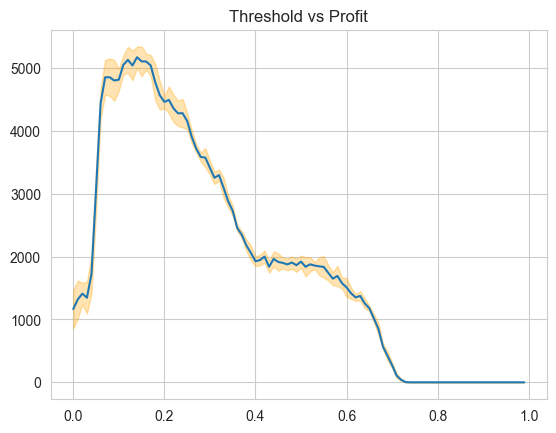

In [276]:
#your code here
plt.title("Threshold vs Profit")
plt.plot(thresholds, profits)
profits_std = np.array(profits_std)
plt.fill_between(thresholds, profits - profits_std, profits + profits_std, alpha=0.3, color='orange')
plt.show()

__Вопрос:__ Замечаете ли вы какую-то закономерность? Для правильного ответа на этот вопрос попробуйте запустить несколько раз и задумайтесь, почему порог получается в какой-то конкретной области?

__Ответ:__ Достигается баланс между звонками всем подряд и только прибыльным клиентам

Каковы значения precision и recall на выбранном пороге? Оцените по кросс-валидации. Также вычислите стандартное отклонение.

In [277]:
#your code here

from sklearn.metrics import precision_score, recall_score

profits = np.array(profits)
best_thr = thresholds[profits.argmax()]

precision, recall = 0, 0

for (train_index, test_index) in cur_split:
        model = LogisticRegression(C=best_c)
        temp = allct.fit_transform(X.iloc[train_index], y[train_index])

        model.fit(temp, y[train_index])

        y_pred = model.predict_proba(allct.transform(X.iloc[test_index]))[:, 1]
        y_pred = (y_pred > best_thr)

        precision += precision_score(y[test_index], y_pred)
        recall += recall_score(y[test_index], y_pred)

print("PR", precision / 4, recall / 4)

PR 0.42483108220904964 0.7867758167608323


Можно пронаблюдать, что наша модель склоняется к более высокому recall. Попробуйте оценить качество модели с помощью `PR-AUC` в зоне recall $\geq$ 0.5. Сделайте это следующим образом:
- выберите только те пороги, на которых достигается необходимый recall,
- затем интерпретируйте отсеченный в единичном квадрате прямоугольник как новый единичный квадрат,
- посчитайте площадь под отсеченной кривой

In [278]:
#your code here

precisions, recalls = [], []
cur_split = list(kf.split(X))

for thr in thresholds:

    precision, recall = 0, 0

    for (train_index, test_index) in cur_split:
        model = LogisticRegression(C=best_c)
        temp = allct.fit_transform(X.iloc[train_index], y[train_index])

        model.fit(temp, y[train_index])

        y_pred = model.predict_proba(allct.transform(X.iloc[test_index]))[:, 1]
        y_pred = (y_pred > thr)

        precision += precision_score(y[test_index], y_pred)
        recall += recall_score(y[test_index], y_pred)
    
    if recall / 4 >= 0.5:
        recalls.append(recall / 4)
        precisions.append(precision / 4)

print(precisions, recalls)

[0.14081770334255544, 0.14082115548530524, 0.1409171314092757, 0.14143917546252183, 0.1442996950236624, 0.17582765817740229, 0.241369576796509, 0.27917979417725425, 0.3013565628540394, 0.30589475955122797, 0.3084522868389824, 0.31858196359609936, 0.34176356265368923, 0.379811660785379, 0.42483108220904964, 0.46691184507352573, 0.4992173733319033, 0.5240916838459339, 0.5387475278547432, 0.5492705464324834, 0.5502609794708134, 0.5527211559946805, 0.5564517931945081, 0.5627327486655657, 0.5703855911421402, 0.5803430225838485, 0.5895763474667001, 0.5985769925186036] [1.25, 1.25, 1.25, 1.2494757245058676, 1.2366299160396397, 1.1224633352750832, 0.9710696007500896, 0.9246254055380713, 0.8965329726767136, 0.8897662074598104, 0.8879140962542598, 0.8822982329587481, 0.8614546523074225, 0.8230723475408963, 0.7867758167608323, 0.7586130872784378, 0.7352543476326061, 0.7079825457000888, 0.6666914546504707, 0.6399804520686225, 0.6218158431459138, 0.6161109909865137, 0.6096765639292365, 0.6010604113

PR-AUC (recall >= 0.5) 0.25974058189989124


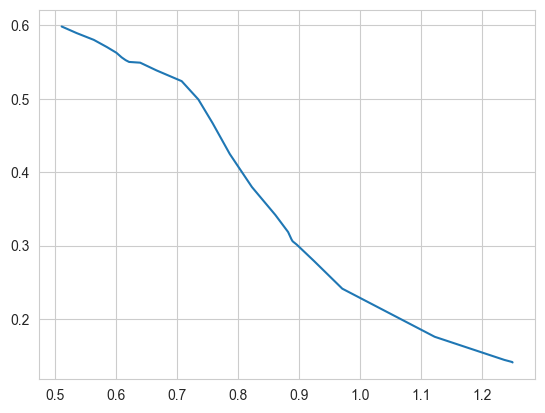

In [279]:
plt.plot(recalls, precisions)
print("PR-AUC (recall >= 0.5)", auc(recalls, precisions))

__Бонус (0.01 балла):__ что вы кушали в день сдачи данного ДЗ на завтрак?

__Ответ:__ Белый монстр и натс